# NHTS 2022 - Data Exploration Notebook
### 2022 NextGen National Household Travel Survey, Version 2.1

**Purpose:** Understand the data before any statistical modelling.

**Research question (future work):**
> *Among a clearly defined class of U.S. trips, how are traveller, household, trip, and
> accessibility characteristics associated with choosing car, public transport, walking, or cycling?*

This notebook covers **only** pre-modelling exploration:
- Understanding the source files and their structure
- Learning what key columns mean
- Validating table relationships
- Defining the study population
- Checking whether the proposed outcome categories have enough observations

---

### Official NHTS Resources
- **Data download:** https://nhts.ornl.gov/downloads
- **Documentation:** https://nhts.ornl.gov/documentation

## Kernel Setup

This notebook was tested with the Anaconda **base** environment, which already contains
all required packages (`pandas`, `numpy`, `matplotlib`, `seaborn`, `openpyxl`).

**To select the correct kernel in JupyterLab / Jupyter Notebook:**

1. Open the notebook.
2. Click **Kernel -> Change Kernel** (JupyterLab) or **Kernel -> Change kernel** (classic Notebook).
3. Select **Python 3 (ipykernel)** (the Anaconda base kernel).

If you created a dedicated `nhts-mode-choice` environment instead, choose:
```
Kernel -> Change Kernel -> Python (NHTS Mode Choice)
```

> **Do not run `pip install` or `conda install` inside notebook cells.**
> Package installation belongs in the terminal / Anaconda prompt before launching Jupyter.

## 1  Environment Diagnostic

In [1]:
import sys
from pathlib import Path

print("=" * 60)
print("ENVIRONMENT DIAGNOSTIC")
print("=" * 60)
print(f"Python version      : {sys.version}")
print(f"Python executable   : {sys.executable}")
print(f"Working directory   : {Path.cwd()}")

try:
    import pandas as pd
    print(f"pandas version      : {pd.__version__}")
except ImportError:
    print("pandas              : NOT INSTALLED")

try:
    import numpy as np
    print(f"numpy version       : {np.__version__}")
except ImportError:
    print("numpy               : NOT INSTALLED")

try:
    import matplotlib
    print(f"matplotlib version  : {matplotlib.__version__}")
except ImportError:
    print("matplotlib          : NOT INSTALLED")

try:
    import seaborn as sns
    print(f"seaborn version     : {sns.__version__}")
    _HAS_SEABORN = True
except ImportError:
    print("seaborn             : not installed (optional)")
    _HAS_SEABORN = False

try:
    import openpyxl
    print(f"openpyxl version    : {openpyxl.__version__}")
    _HAS_OPENPYXL = True
except ImportError:
    print("openpyxl            : NOT INSTALLED - Excel codebook loading will be skipped")
    _HAS_OPENPYXL = False

ENVIRONMENT DIAGNOSTIC
Python version      : 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
Python executable   : C:\ProgramData\anaconda3\python.exe
Working directory   : D:\StatProject
pandas version      : 2.2.2
numpy version       : 1.26.4
matplotlib version  : 3.9.2
seaborn version     : 0.13.2
openpyxl version    : 3.1.5


## 2  Dataset Structure

The 2022 NHTS provides four main data tables.  Think of them as a small relational database:

| Table | What one row means | Primary key | Role in this project |
|---|---|---|---|
| **Household** (`hhv2pub.csv`) | One surveyed household | `HOUSEID` | Background context (income, size, vehicles, location) |
| **Person** (`perv2pub.csv`) | One person within a household | `HOUSEID + PERSONID` | Traveller attributes (age, sex, employment, driving licence) |
| **Vehicle** (`vehv2pub.csv`) | One vehicle owned by a household | `HOUSEID + VEHID` | Vehicle availability context |
| **Trip** (`tripv2pub.csv`) | One trip made by one person on one day | `TDCASEID` (or `HOUSEID + PERSONID + SEQ_TRIPID`) | **Fact table** -- the unit of analysis for mode choice |

### Relationships

```
Household (1) --> Person  (many)   linked by  HOUSEID
Household (1) --> Vehicle (many)   linked by  HOUSEID
Household (1) --> Trip    (many)   linked by  HOUSEID
Person    (1) --> Trip    (many)   linked by  HOUSEID + PERSONID
Vehicle  (0/1)--> Trip    (many)   linked by  HOUSEID + VEHID   (vehicle trips only)
```

### Important: key uniqueness

- `HOUSEID` is **not** unique in the person, vehicle, or trip tables.
- `PERSONID` is **only unique within a household** -- two different households can both have
  a person with `PERSONID = 1`.
- Always join on **both** `HOUSEID` and `PERSONID` together; joining on `PERSONID` alone is
  **incorrect** and will produce wrong matches.

### Denormalisation note

The 2022 NHTS public-use files are **pre-merged / denormalised**: the trip file already contains
many household and person columns (`RAIL`, `HHVEHCNT`, `HHSIZE`, `HHFAMINC`, `R_AGE`,
`R_SEX_IMP`, etc.).  This means many variables of interest can be read directly from the trip
table without an explicit join.  We still validate relationships and perform explicit joins to
confirm data integrity.

## 3  Configuration and Imports

In [2]:
# -----------------------------------------------------------------------
# CONFIGURATION  <-- Change DATA_DIR to match your local folder
# -----------------------------------------------------------------------
from pathlib import Path

# Default: looks for a sub-folder called 'Data' in the notebook directory.
DATA_DIR = Path("./Data")

# -- Windows example -----------------------------------------------------
# DATA_DIR = Path(r"C:\Users\YourName\Downloads\NHTS_2022")

# -- macOS / Linux example -----------------------------------------------
# DATA_DIR = Path("/Users/YourName/Downloads/NHTS_2022")

# DATA_DIR must point to the *folder* that contains hhv2pub.csv etc.,
# NOT to the ZIP file itself.

EXPORT_OUTPUT = True                                  # Section 17 -- export toggle
OUTPUT_PATH   = Path("./nhts_weekday_commute_analysis.csv")

In [3]:
# -----------------------------------------------------------------------
# IMPORTS
# -----------------------------------------------------------------------
import re
import sys
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

try:
    import seaborn as sns
    _HAS_SEABORN = True
    sns.set_theme(style="whitegrid", palette="muted")
except ImportError:
    _HAS_SEABORN = False

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 80)
pd.set_option("display.float_format", "{:,.2f}".format)

print(f"DATA_DIR  : {DATA_DIR.resolve()}")
print(f"Exists    : {DATA_DIR.exists()}")

DATA_DIR  : D:\StatProject\Data
Exists    : True


## 4  Automatic File Discovery and Loading

The cells below search recursively (case-insensitively) for the four NHTS tables and any
Excel codebook / data dictionary.  If a file is missing, an informative message is printed
instead of crashing.

In [4]:
# -----------------------------------------------------------------------
# FILE PATTERNS - stem fragment -> logical label
# -----------------------------------------------------------------------
FILE_STEMS = {
    "household": "hhv2pub",
    "person":    "perv2pub",
    "trip":      "tripv2pub",
    "vehicle":   "vehv2pub",
}


def _find_csv(directory, stem_fragment):
    """Search recursively for a CSV file whose stem contains stem_fragment (case-insensitive)."""
    if not directory.exists():
        return None
    frag = stem_fragment.lower()
    for p in sorted(directory.rglob("*.csv")):
        if frag in p.stem.lower():
            return p
    return None


def _find_excel(directory):
    """Search recursively for the first Excel file (.xlsx or .xls)."""
    if not directory.exists():
        return None
    for ext in ("*.xlsx", "*.xls"):
        hits = sorted(directory.rglob(ext))
        if hits:
            return hits[0]
    return None


_found = {label: _find_csv(DATA_DIR, stem) for label, stem in FILE_STEMS.items()}
codebook_path = _find_excel(DATA_DIR)

rows = []
for label, path in _found.items():
    rows.append({
        "Table":    label,
        "Found":    "YES" if path else "NO",
        "Filename": path.name if path else "NOT FOUND",
        "Path":     str(path.resolve()) if path else "--",
    })
rows.append({
    "Table":    "codebook (Excel)",
    "Found":    "YES" if codebook_path else "NO",
    "Filename": codebook_path.name if codebook_path else "NOT FOUND",
    "Path":     str(codebook_path.resolve()) if codebook_path else "--",
})

print("=" * 70)
print("FILE INVENTORY")
print("=" * 70)
print(pd.DataFrame(rows).to_string(index=False))

if not any(_found.values()):
    print("\n*** No data files found. ***")
    print(f"Check DATA_DIR = {DATA_DIR.resolve()}")
    print("It should point to the folder containing the extracted CSV files.")

FILE INVENTORY
           Table Found      Filename                              Path
       household   YES   hhv2pub.csv   D:\StatProject\Data\hhv2pub.csv
          person   YES  perv2pub.csv  D:\StatProject\Data\perv2pub.csv
            trip   YES tripv2pub.csv D:\StatProject\Data\tripv2pub.csv
         vehicle   YES  vehv2pub.csv  D:\StatProject\Data\vehv2pub.csv
codebook (Excel)    NO     NOT FOUND                                --


In [5]:
# -----------------------------------------------------------------------
# LOAD CSV FILES
# -----------------------------------------------------------------------
_dfs = {}
_inv_rows = []

for label, path in _found.items():
    if path is None:
        print(f"[SKIP] {label} table not found.")
        _dfs[label] = None
        continue
    df = pd.read_csv(path, low_memory=False)
    _dfs[label] = df
    mem_mb = df.memory_usage(deep=True).sum() / 1_048_576
    _inv_rows.append({
        "Table":     label,
        "Filename":  path.name,
        "Rows":      f"{len(df):,}",
        "Columns":   len(df.columns),
        "Memory MB": f"{mem_mb:.1f}",
    })

hh   = _dfs.get("household")
per  = _dfs.get("person")
trip = _dfs.get("trip")
veh  = _dfs.get("vehicle")

print("=" * 65)
print("LOADED TABLE SUMMARY")
print("=" * 65)
if _inv_rows:
    print(pd.DataFrame(_inv_rows).to_string(index=False))
else:
    print("No tables loaded.")

LOADED TABLE SUMMARY
    Table      Filename   Rows  Columns Memory MB
household   hhv2pub.csv  7,893       43       2.6
   person  perv2pub.csv 16,997      153      19.8
     trip tripv2pub.csv 31,074      102      24.2
  vehicle  vehv2pub.csv 14,684       55       6.2


## 5  Key Validation

A **primary key** is a column (or combination of columns) that uniquely identifies every row
in a table.  Before joining tables we must confirm the keys work as expected -- otherwise
joins can silently duplicate or drop rows.

**Special missing-value codes used throughout the NHTS:**

| Code | Meaning |
|------|---------|
| `-1` | Legitimate / appropriate skip (questionnaire logic routed the respondent away from this question -- may carry real information, e.g. "not applicable") |
| `-7` | Prefer not to answer |
| `-8` | Do not know |
| `-9` | Not ascertained / unavailable |

> **Rule:** Never replace these codes with `NaN` in the raw tables without first reading the
> individual variable's codebook definition.

In [6]:
def validate_key(df, key_cols, table_name):
    """Return a one-row summary DataFrame checking whether key_cols form a primary key."""
    if df is None:
        return pd.DataFrame([{"Table": table_name, "Status": "TABLE NOT LOADED"}])

    missing_cols = [c for c in key_cols if c not in df.columns]
    if missing_cols:
        return pd.DataFrame([{
            "Table":       table_name,
            "Key columns": str(key_cols),
            "Status":      f"MISSING COLUMNS: {missing_cols}",
        }])

    total_rows  = len(df)
    null_rows   = int(df[key_cols].isnull().any(axis=1).sum())
    unique_keys = df.groupby(key_cols, sort=False).ngroups
    dup_rows    = total_rows - unique_keys

    return pd.DataFrame([{
        "Table":          table_name,
        "Key columns":    " + ".join(key_cols),
        "Total rows":     total_rows,
        "Null-key rows":  null_rows,
        "Unique keys":    unique_keys,
        "Duplicate rows": dup_rows,
        "Key is unique?": "YES" if dup_rows == 0 else f"NO -- {dup_rows:,} duplicates",
    }])


key_results = pd.concat([
    validate_key(hh,   ["HOUSEID"],                           "household"),
    validate_key(per,  ["HOUSEID", "PERSONID"],               "person"),
    validate_key(veh,  ["HOUSEID", "VEHID"],                  "vehicle"),
    validate_key(trip, ["TDCASEID"],                          "trip (TDCASEID)"),
    validate_key(trip, ["HOUSEID", "PERSONID", "SEQ_TRIPID"], "trip (composite)"),
], ignore_index=True)

print("=" * 80)
print("KEY VALIDATION RESULTS")
print("=" * 80)
print(key_results.to_string(index=False))

KEY VALIDATION RESULTS
           Table                     Key columns  Total rows  Null-key rows  Unique keys  Duplicate rows Key is unique?
       household                         HOUSEID        7893              0         7893               0            YES
          person              HOUSEID + PERSONID       16997              0        16997               0            YES
         vehicle                 HOUSEID + VEHID       14684              0        14684               0            YES
 trip (TDCASEID)                        TDCASEID       31074              0        31074               0            YES
trip (composite) HOUSEID + PERSONID + SEQ_TRIPID       31074              0        31074               0            YES


## 6  Relationship Validation

Here we check **referential integrity** -- for example, every person record must have a
matching household record.  If a trip has no matching person, that trip may need to be
excluded from analysis or investigated further.

In [7]:
def validate_relationship(child_df, child_name, child_keys,
                          parent_df, parent_name, parent_keys):
    """Check that every row in child_df has a matching row in parent_df."""
    if child_df is None or parent_df is None:
        return pd.DataFrame([{
            "Relationship": f"{child_name} -> {parent_name}",
            "Status": "SKIPPED (table not loaded)",
        }])

    missing_child  = [c for c in child_keys  if c not in child_df.columns]
    missing_parent = [c for c in parent_keys if c not in parent_df.columns]
    if missing_child or missing_parent:
        return pd.DataFrame([{
            "Relationship": f"{child_name} -> {parent_name}",
            "Status": f"MISSING COLS -- child:{missing_child} parent:{missing_parent}",
        }])

    child_rows     = len(child_df)
    parent_keys_df = parent_df[parent_keys].drop_duplicates()
    rename_map     = dict(zip(parent_keys, child_keys))
    parent_keys_df = parent_keys_df.rename(columns=rename_map)

    merged    = child_df[child_keys].merge(
        parent_keys_df, on=child_keys, how="left", indicator=True,
    )
    matched   = int((merged["_merge"] == "both").sum())
    unmatched = int((merged["_merge"] == "left_only").sum())
    pct       = matched / child_rows * 100 if child_rows else 0

    return pd.DataFrame([{
        "Relationship":  f"{child_name} -> {parent_name}",
        "Child rows":    child_rows,
        "Matched":       matched,
        "Unmatched":     unmatched,
        "Match %":       f"{pct:.2f}%",
        "Status":        "OK" if unmatched == 0 else f"WARNING -- {unmatched:,} unmatched",
    }])


rel_results = pd.concat([
    validate_relationship(per,  "person",  ["HOUSEID"],
                          hh,   "household", ["HOUSEID"]),
    validate_relationship(veh,  "vehicle", ["HOUSEID"],
                          hh,   "household", ["HOUSEID"]),
    validate_relationship(trip, "trip",    ["HOUSEID"],
                          hh,   "household", ["HOUSEID"]),
    validate_relationship(trip, "trip",    ["HOUSEID", "PERSONID"],
                          per,  "person",    ["HOUSEID", "PERSONID"]),
], ignore_index=True)

print("=" * 80)
print("RELATIONSHIP VALIDATION RESULTS")
print("=" * 80)
print(rel_results.to_string(index=False))

RELATIONSHIP VALIDATION RESULTS
        Relationship  Child rows  Matched  Unmatched Match % Status
 person -> household       16997    16997          0 100.00%     OK
vehicle -> household       14684    14684          0 100.00%     OK
   trip -> household       31074    31074          0 100.00%     OK
      trip -> person       31074    31074          0 100.00%     OK


## 7  Codebook Search

The official NHTS codebook explains every variable's codes and meanings.
**Never guess a variable's meaning from its abbreviation.**

An Excel codebook was not found in the current data directory.  The NHTS documentation is
available online at https://nhts.ornl.gov/documentation.

If you download the Excel codebook (e.g., `NHTS2022_CodeBook.xlsx`) and place it in the
same folder as the CSV files, the `search_codebook()` function will load and search it
automatically.

In [8]:
import re as _re

_codebook_sheets = None


def _load_codebook():
    """Load all sheets from the Excel codebook (once) and cache the result."""
    global _codebook_sheets
    if _codebook_sheets is not None:
        return _codebook_sheets

    if codebook_path is None:
        print("[INFO] No Excel codebook found in DATA_DIR.")
        print("       Download it from https://nhts.ornl.gov/documentation")
        print("       and place it in:", DATA_DIR.resolve())
        return None

    try:
        import openpyxl  # noqa: F401
    except ImportError:
        print("[SKIP] openpyxl not installed -- cannot read Excel codebook.")
        return None

    print(f"Loading codebook: {codebook_path.name} ...", end=" ", flush=True)
    try:
        _codebook_sheets = pd.read_excel(codebook_path, sheet_name=None)
        print(f"OK ({len(_codebook_sheets)} sheets)")
        return _codebook_sheets
    except Exception as exc:
        print(f"ERROR: {exc}")
        return None


def search_codebook(term):
    """
    Search every cell in every sheet of the Excel codebook for term.
    Case-insensitive. Returns matching rows with a Source_Sheet column prepended.
    """
    sheets = _load_codebook()
    if sheets is None:
        print(f"[search_codebook] No codebook available. Searched for: '{term}'")
        print("  -> Look up the variable at https://nhts.ornl.gov/documentation")
        return None

    rx = _re.compile(_re.escape(term), _re.IGNORECASE)
    results = []
    for sheet_name, df in sheets.items():
        mask = df.apply(
            lambda col: col.astype(str).str.contains(rx, na=False)
        ).any(axis=1)
        hits = df[mask].copy()
        if not hits.empty:
            hits.insert(0, "Source_Sheet", sheet_name)
            results.append(hits)

    if not results:
        print(f"No entries found for '{term}'.")
        return pd.DataFrame()

    out = pd.concat(results, ignore_index=True)
    print(f"Found {len(out)} row(s) matching '{term}':")
    return out


# Example searches (safe -- shows instructions if no codebook file is present)
print("Codebook search examples:")
for _term in ["TRPTRANS", "HHVEHCNT", "population density", "survey weight"]:
    print(f"\n--- search_codebook('{_term}') ---")
    search_codebook(_term)

Codebook search examples:

--- search_codebook('TRPTRANS') ---
[INFO] No Excel codebook found in DATA_DIR.
       Download it from https://nhts.ornl.gov/documentation
       and place it in: D:\StatProject\Data
[search_codebook] No codebook available. Searched for: 'TRPTRANS'
  -> Look up the variable at https://nhts.ornl.gov/documentation

--- search_codebook('HHVEHCNT') ---
[INFO] No Excel codebook found in DATA_DIR.
       Download it from https://nhts.ornl.gov/documentation
       and place it in: D:\StatProject\Data
[search_codebook] No codebook available. Searched for: 'HHVEHCNT'
  -> Look up the variable at https://nhts.ornl.gov/documentation

--- search_codebook('population density') ---
[INFO] No Excel codebook found in DATA_DIR.
       Download it from https://nhts.ornl.gov/documentation
       and place it in: D:\StatProject\Data
[search_codebook] No codebook available. Searched for: 'population density'
  -> Look up the variable at https://nhts.ornl.gov/documentation

--- s

## 8  Column-Profiling Tools

Two reusable functions:

- **`column_profile(df)`** -- summary statistics for every column in a table.
- **`inspect_variable(df, column, weight=None)`** -- detailed frequency table for one
  variable, with optional survey-weighted percentages.

### NHTS special missing-value codes

| Code | Meaning |
|------|---------|
| `-1` | Appropriate / legitimate skip -- questionnaire logic routed this respondent away from the question. This is **not** the same as "data unavailable"; it may carry real information (e.g. "not applicable" for a non-worker). |
| `-7` | Prefer not to answer |
| `-8` | Do not know |
| `-9` | Not ascertained -- information is simply unavailable |

Always check the individual variable's codebook entry to decide how to treat these codes.

In [9]:
_SPECIAL_CODES = {-1, -7, -8, -9}


def _count_specials(series):
    """Count values matching NHTS special missing codes (-1, -7, -8, -9)."""
    try:
        num = pd.to_numeric(series, errors="coerce")
        return int(num.isin(_SPECIAL_CODES).sum())
    except Exception:
        return 0


def column_profile(df, n_sample=5):
    """
    Return a summary DataFrame: dtype, n_unique, ordinary-missing count/pct,
    special-code count/pct, and sample values for every column.
    """
    if df is None:
        print("Table not loaded.")
        return pd.DataFrame()

    rows = []
    n = len(df)
    for col in df.columns:
        s         = df[col]
        n_null    = int(s.isna().sum())
        n_special = _count_specials(s)
        n_unique  = s.nunique(dropna=False)
        sample    = list(s.dropna().unique()[:n_sample])
        rows.append({
            "column":        col,
            "dtype":         str(s.dtype),
            "n_unique":      n_unique,
            "null_count":    n_null,
            "null_pct":      f"{n_null/n*100:.1f}%",
            "special_count": n_special,
            "special_pct":   f"{n_special/n*100:.1f}%",
            "sample_values": sample,
        })
    return pd.DataFrame(rows)


def inspect_variable(df, column, weight=None, max_rows=30):
    """
    Display a frequency table for column in df.
    If weight is provided and exists in df, also shows weighted totals/percentages.
    """
    if df is None:
        print("[inspect_variable] Table not loaded.")
        return None
    if column not in df.columns:
        avail = list(df.columns)[:10]
        print(f"[inspect_variable] Column '{column}' not found. Available: {avail} ...")
        return None

    s      = df[column]
    total  = len(s)
    counts = s.value_counts(dropna=False).rename("unweighted_count")
    pct    = (counts / total * 100).rename("unweighted_pct_%")
    result = pd.concat([counts, pct], axis=1).reset_index()
    result.columns = [column, "unweighted_count", "unweighted_pct_%"]

    if weight and weight in df.columns:
        w_totals = df.groupby(column, dropna=False)[weight].sum().rename("weighted_total")
        w_sum    = w_totals.sum()
        w_pct    = (w_totals / w_sum * 100).rename("weighted_pct_%") if w_sum > 0 else w_totals * 0
        result   = result.merge(
            pd.concat([w_totals, w_pct], axis=1).reset_index(),
            on=column, how="left",
        )
    elif weight:
        print(f"  [Note] Weight column '{weight}' not found -- showing unweighted only.")

    result = result.head(max_rows)
    sep = "=" * 60
    wt_note = f"  (weight: {weight})" if weight and weight in df.columns else ""
    print(f"\n{sep}")
    print(f"Variable: {column}{wt_note}")
    print(f"Total records: {total:,}")
    print(sep)
    print(result.to_string(index=False))
    return result

### 8.1  Variable Inspection Examples

In [10]:
# Safe inspection examples -- each checks that the table and column exist first.
# The trip table is heavily denormalised, so many household variables are present there.
_examples = [
    (trip, "TRPTRANS",  "WTTRDFIN",  "trip", "Transport mode chosen"),
    (trip, "TRIPPURP",  "WTTRDFIN",  "trip", "Trip purpose"),
    (trip, "TDWKND",    "WTTRDFIN",  "trip", "Weekday / weekend indicator"),
    (hh,   "HHVEHCNT",  None,        "hh",   "Household vehicle count"),
    (hh,   "HHFAMINC",  None,        "hh",   "Household income category"),
    (per,  "R_AGE",     None,        "per",  "Person age"),
    (hh,   "RAIL",      None,        "hh",   "Rail transit in MSA"),
    (hh,   "URBRUR",    None,        "hh",   "Urban/rural classification"),
]

for df_ref, col, wt, tbl_label, description in _examples:
    if df_ref is not None and col in df_ref.columns:
        print(f"\n[{tbl_label}] {description}")
        inspect_variable(df_ref, col, weight=wt)
    else:
        print(f"[SKIP] {col} not available in the {tbl_label} table.")


[trip] Transport mode chosen

Variable: TRPTRANS  (weight: WTTRDFIN)
Total records: 31,074
 TRPTRANS  unweighted_count  unweighted_pct_%     weighted_total  weighted_pct_%
        1             11777             37.90 101,726,646,688.20           40.09
        3             10384             33.42  76,732,037,643.95           30.24
        4              3302             10.63  25,499,402,941.12           10.05
       20              2103              6.77  17,390,867,219.07            6.85
        2              1881              6.05  16,034,016,170.31            6.32
        9               650              2.09   7,295,049,228.20            2.87
       18               298              0.96   2,393,493,730.83            0.94
        8               190              0.61   2,362,638,066.11            0.93
       11               109              0.35     996,954,772.07            0.39
       16               109              0.35   1,029,359,423.60            0.41
       14        

## 9  Candidate-Variable Catalogue

The table below lists every variable proposed for the mode-choice model, showing which
table it is found in and whether it is available.

In [11]:
CANDIDATE_VARIABLES = {
    # -- Identifiers --
    "HOUSEID":    ("identifier",    "Household identifier -- part of every composite key"),
    "PERSONID":   ("identifier",    "Person within household -- NOT unique on its own"),
    "TDCASEID":   ("identifier",    "Unique trip-case identifier (preferred trip primary key)"),
    "SEQ_TRIPID": ("identifier",    "Sequential trip number within person-day"),
    # -- Outcome --
    "TRPTRANS":   ("outcome",       "Transport mode -- the variable to be modelled"),
    # -- Trip definition --
    "TDWKND":     ("trip_def",      "Weekday (code 2) vs. weekend (code 1)"),
    "TRIPPURP":   ("trip_def",      "Trip purpose category"),
    "WHYFROM":    ("trip_def",      "Why leaving origin"),
    "WHYTO":      ("trip_def",      "Why going to destination"),
    "TDAYDATE":   ("trip_def",      "Travel date (some Jan 2023 dates are included)"),
    "STRTTIME":   ("trip_def",      "Trip start time"),
    # -- Distance --
    "GCDWORK":    ("distance",      "Great-circle distance to work in person table (more mode-neutral)"),
    "TRPMILES":   ("distance",      "Trip distance in miles (may be partly mode-dependent)"),
    # -- Traveller attributes --
    "R_AGE":      ("traveller",     "Person age (direct field; _IMP variant not in V2.1 public file)"),
    "R_SEX_IMP":  ("traveller",     "Person sex (imputed)"),
    "EDUC":       ("traveller",     "Education level"),
    "WORKER":     ("traveller",     "Worker status"),
    "WKFTPT":     ("traveller",     "Full/part-time worker -- NOT in V2.1 public files"),
    "DRIVER":     ("traveller",     "Whether person is a licensed driver"),
    # -- Household attributes --
    "HHFAMINC":   ("household",     "Household income category"),
    "HHSIZE":     ("household",     "Number of persons in household"),
    "HHVEHCNT":   ("household",     "Number of household vehicles"),
    "DRVRCNT":    ("household",     "Number of licensed drivers in household"),
    "WRKCOUNT":   ("household",     "Number of workers in household"),
    # -- Accessibility --
    "RAIL":       ("accessibility", "Whether rail transit is available in the MSA"),
    "MSACAT":     ("accessibility", "MSA size category"),
    "URBRUR":     ("accessibility", "Urban / rural classification"),
    "HBPPOPDN":   ("accessibility", "Population density at home block group"),
    "HTPPOPDN":   ("accessibility", "Transit stop density at home block group"),
    "DBPPOPDN":   ("accessibility", "Population density at destination block group"),
    "DTPPOPDN":   ("accessibility", "Transit stop density at destination block group"),
    # -- Survey design --
    "WTTRDFIN":   ("survey_design", "Seven-day trip weight"),
    "WTTRDFIN5D": ("survey_design", "Five-weekday trip weight (preferred for weekday estimates)"),
    "STRATUMID":  ("survey_design", "Sampling stratum identifier"),
}


def _find_var_in_tables(varname):
    """Report which loaded tables contain varname."""
    found_in = [
        lbl for lbl, df_ref in [("hh", hh), ("per", per), ("trip", trip), ("veh", veh)]
        if df_ref is not None and varname in df_ref.columns
    ]
    return ", ".join(found_in) if found_in else "NOT FOUND"


catalogue_rows = []
for var, (category, description) in CANDIDATE_VARIABLES.items():
    found_in = _find_var_in_tables(var)
    catalogue_rows.append({
        "Variable":    var,
        "Category":    category,
        "Found in":    found_in,
        "Status":      "OK" if found_in != "NOT FOUND" else "MISSING",
        "Description": description,
    })

cat_df = pd.DataFrame(catalogue_rows)
print("=" * 95)
print("CANDIDATE-VARIABLE CATALOGUE")
print("=" * 95)
print(cat_df.to_string(index=False))

missing_vars = cat_df[cat_df["Status"] == "MISSING"]
if not missing_vars.empty:
    print(f"\n[NOTE] {len(missing_vars)} variable(s) not found in loaded data:")
    for _, row in missing_vars.iterrows():
        print(f"  * {row['Variable']} -- {row['Description']}")

CANDIDATE-VARIABLE CATALOGUE
  Variable      Category           Found in  Status                                                       Description
   HOUSEID    identifier hh, per, trip, veh      OK               Household identifier -- part of every composite key
  PERSONID    identifier          per, trip      OK                  Person within household -- NOT unique on its own
  TDCASEID    identifier               trip      OK          Unique trip-case identifier (preferred trip primary key)
SEQ_TRIPID    identifier               trip      OK                          Sequential trip number within person-day
  TRPTRANS       outcome               trip      OK                     Transport mode -- the variable to be modelled
    TDWKND      trip_def               trip      OK                             Weekday (code 2) vs. weekend (code 1)
  TRIPPURP      trip_def               trip      OK                                             Trip purpose category
   WHYFROM      trip_def   

## 10  Transport Mode Mapping

The `TRPTRANS` variable uses numeric codes.  We create a grouped `mode_4cat` variable:

| Group | Raw codes | Labels |
|---|---|---|
| **car** | 01, 02, 03, 04 | Car, Van, SUV/Crossover, Pickup truck |
| **public_transport** | 08, 10, 11, 12, 13 | Bus, Streetcar, Subway, Commuter rail, Amtrak |
| **cycling** | 18 | Bicycle |
| **walking** | 20 | Walked |
| **other_or_excluded** | all others | TNCs, taxis, school buses, aircraft, etc. |

Modes are coded as integers in the file but may load as strings, integers, or floats --
the mapping handles all three.

RAW TRPTRANS FREQUENCIES (top 25)
TRPTRANS
1     11777
3     10384
4      3302
20     2103
2      1881
9       650
18      298
8       190
11      109
16      109
14       71
21       65
7        55
12       33
6        10
15        9
10        9
17        9
19        6
13        4

GROUPED MODE FREQUENCIES
        mode_4cat  unweighted_count     weighted_total  unweighted_pct_%  weighted_pct_%
              car             27344 219,992,103,443.58             88.00           86.69
 public_transport               345   3,720,463,729.97              1.11            1.47
          cycling               298   2,393,493,730.83              0.96            0.94
          walking              2103  17,390,867,219.07              6.77            6.85
other_or_excluded               984  10,257,608,383.29              3.17            4.04


C:\Users\Wow\AppData\Local\Temp\ipykernel_42536\642098335.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
C:\Users\Wow\AppData\Local\Temp\ipykernel_42536\642098335.py:70: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")


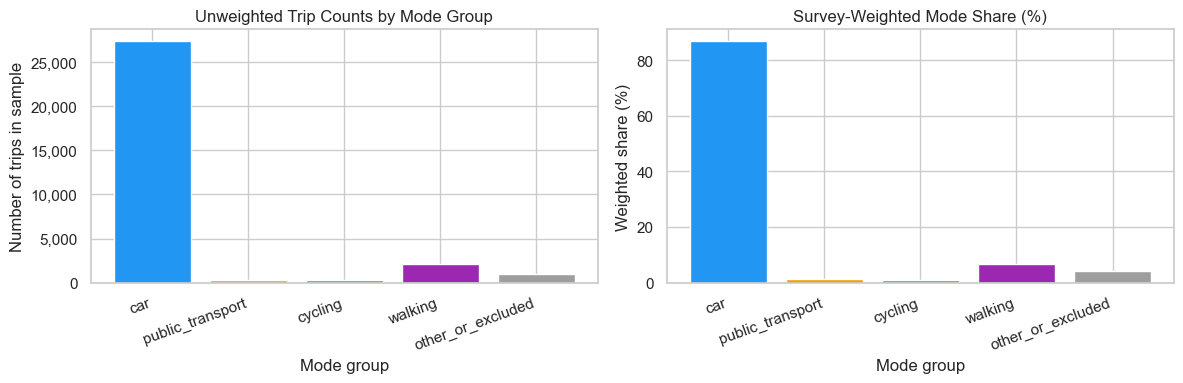

In [12]:
MODE_MAP = {
    1 : "car",               # Car
    2 : "car",               # Van
    3 : "car",               # SUV / Crossover
    4 : "car",               # Pickup truck
    8 : "public_transport",  # Public or commuter bus
    10: "public_transport",  # Streetcar / trolley
    11: "public_transport",  # Subway / elevated rail
    12: "public_transport",  # Commuter rail
    13: "public_transport",  # Amtrak
    18: "cycling",           # Bicycle
    20: "walking",           # Walked
}
MODE_ORDER  = ["car", "public_transport", "cycling", "walking", "other_or_excluded"]
MODE_COLORS = ["#2196F3", "#FF9800", "#4CAF50", "#9C27B0", "#9E9E9E"]


def map_modes(series):
    """Map TRPTRANS codes to four analytical categories. Handles int, float, and str."""
    numeric = pd.to_numeric(series, errors="coerce").round().astype("Int64")
    return numeric.map(MODE_MAP).fillna("other_or_excluded").astype("category")


if trip is not None and "TRPTRANS" in trip.columns:
    trip = trip.copy()
    trip["mode_4cat"] = map_modes(trip["TRPTRANS"])

    print("=" * 60)
    print("RAW TRPTRANS FREQUENCIES (top 25)")
    print("=" * 60)
    print(trip["TRPTRANS"].value_counts(dropna=False).head(25).to_string())

    # Build grouped frequency table
    id_col = "TDCASEID" if "TDCASEID" in trip.columns else "TRPTRANS"
    if "WTTRDFIN" in trip.columns:
        grp = (
            trip.groupby("mode_4cat", observed=False)
            .agg(unweighted_count=(id_col, "count"), weighted_total=("WTTRDFIN", "sum"))
            .reindex(MODE_ORDER).fillna(0).reset_index()
        )
        total_uw = grp["unweighted_count"].sum()
        total_wt = grp["weighted_total"].sum()
        grp["unweighted_pct_%"] = (grp["unweighted_count"] / total_uw * 100).round(2)
        grp["weighted_pct_%"]   = (grp["weighted_total"]   / total_wt * 100).round(2)
        print("\n" + "=" * 60)
        print("GROUPED MODE FREQUENCIES")
        print("=" * 60)
        print(grp.to_string(index=False))
    else:
        grp = (trip["mode_4cat"].value_counts(dropna=False)
               .reindex(MODE_ORDER).fillna(0).rename("count").reset_index())
        grp.columns = ["mode_4cat", "count"]
        print("\nGrouped counts (no weight column found):")
        print(grp.to_string(index=False))

    # Bar chart
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    if "WTTRDFIN" in trip.columns:
        axes[0].bar(grp["mode_4cat"], grp["unweighted_count"], color=MODE_COLORS)
        axes[0].set_title("Unweighted Trip Counts by Mode Group")
        axes[0].set_ylabel("Number of trips in sample")
        axes[0].yaxis.set_major_formatter(
            mticker.FuncFormatter(lambda x, _: f"{int(x):,}")
        )
        axes[1].bar(grp["mode_4cat"], grp["weighted_pct_%"], color=MODE_COLORS)
        axes[1].set_title("Survey-Weighted Mode Share (%)")
        axes[1].set_ylabel("Weighted share (%)")
    for ax in axes:
        ax.set_xlabel("Mode group")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
    plt.tight_layout()
    plt.show()
else:
    grp = None
    print("[SKIP] TRPTRANS not available in trip table.")

## 11  Safe Table Joining

The trip file is already **denormalised** -- it already contains many household and person
columns (`RAIL`, `HHVEHCNT`, `R_AGE`, etc.).  The function below adds *only* columns
that are not already present, preventing duplicate `_x` / `_y` columns.

For every join we verify that the number of trip rows does not increase.

In [13]:
def safe_left_join(base_df, other_df, join_keys, base_name="base", other_name="other"):
    """
    Left-join other_df onto base_df.
    Only adds columns absent from base_df.
    Raises RuntimeError if trip rows increase unexpectedly.
    """
    if other_df is None:
        print(f"[SKIP] {other_name} table not loaded.")
        return base_df

    rows_before = len(base_df)
    cols_to_add = [c for c in other_df.columns
                   if c not in base_df.columns or c in join_keys]
    other_slim  = other_df[cols_to_add].drop_duplicates(subset=join_keys)
    result      = base_df.merge(other_slim, on=join_keys, how="left", validate="many_to_one")
    rows_after  = len(result)
    new_cols    = [c for c in result.columns if c not in base_df.columns]

    status = "OK -- unchanged" if rows_before == rows_after else "WARNING -- CHANGED"
    print(f"  Join {base_name} <- {other_name} on {join_keys}")
    print(f"    Rows before : {rows_before:,}")
    print(f"    Rows after  : {rows_after:,}  ({status})")
    print(f"    New columns : {len(new_cols)}  (first 5: {new_cols[:5]})")

    if rows_after > rows_before:
        raise RuntimeError(
            f"JOIN INCREASED ROWS: {base_name} had {rows_before:,}, now {rows_after:,}. "
            f"Investigate duplicate keys in {other_name}[{join_keys}]."
        )
    return result


print("Building analytical base table from trip data ...")
print("Trip file is already denormalised; explicit joins add only missing columns.\n")

if trip is not None:
    analytical = trip.copy()
    print(f"Starting: {len(analytical):,} rows x {len(analytical.columns)} columns")

    if per is not None:
        analytical = safe_left_join(
            analytical, per,
            join_keys=["HOUSEID", "PERSONID"],
            base_name="trip", other_name="person",
        )
    if hh is not None:
        analytical = safe_left_join(
            analytical, hh,
            join_keys=["HOUSEID"],
            base_name="trip+person", other_name="household",
        )

    print(f"\nFinal: {len(analytical):,} rows x {len(analytical.columns)} columns")

    if "mode_4cat" not in analytical.columns and "TRPTRANS" in analytical.columns:
        analytical["mode_4cat"] = map_modes(analytical["TRPTRANS"])
else:
    analytical = None
    print("[SKIP] Trip table not loaded; analytical table not created.")

Building analytical base table from trip data ...
Trip file is already denormalised; explicit joins add only missing columns.

Starting: 31,074 rows x 103 columns
  Join trip <- person on ['HOUSEID', 'PERSONID']
    Rows before : 31,074
    Rows after  : 31,074  (OK -- unchanged)
    New columns : 116  (first 5: ['WTPERFIN', 'WTPERFIN5D', 'WTPERFIN2D', 'R_RELAT', 'GCDWORK'])
  Join trip+person <- household on ['HOUSEID']
    Rows before : 31,074
    Rows after  : 31,074  (OK -- unchanged)
    New columns : 11  (first 5: ['WTHHFIN', 'WTHHFIN5D', 'WTHHFIN2D', 'HOMETYPE', 'CNTTDHH'])

Final: 31,074 rows x 230 columns


## 12  Proposed Study Population (Weekday Commute Trips)

We apply exploratory filters to define a candidate study population:

1. **Adult** -- age >= 18 (`R_AGE >= 18`)
2. **Weekday** -- `TDWKND = 2`
   *Note: some 2022 survey travel dates fall in January 2023. These are legitimate
   weekday observations and are **not** silently removed.*
3. **Home-based work trip** -- `TRIPPURP = 1`
4. **Modal focus** -- mode is car, public_transport, cycling, or walking

### Why these filters?

- **Adult-only** removes school trips and child travel patterns.
- **Weekday-only** focuses on commute-context mode choice and matches `WTTRDFIN5D`.
- **Home-based work** gives a relatively homogeneous trip purpose.
- **Mode restriction** limits the outcome to the four categories of interest.

> These are *exploratory* filters for a first feasibility check -- not a final sample.

In [14]:
if analytical is not None:
    print("Pre-filter variable distributions:\n")
    for col, label in [
        ("TDWKND",    "Weekday indicator"),
        ("TRIPPURP",  "Trip purpose"),
        ("mode_4cat", "Mode group"),
    ]:
        if col in analytical.columns:
            print(f"  {col} ({label}):")
            wt_col = "WTTRDFIN5D" if "WTTRDFIN5D" in analytical.columns else None
            inspect_variable(analytical, col, weight=wt_col, max_rows=15)
            print()

    print("\nApplying filters ...")
    n0 = len(analytical)

    f1 = (analytical["R_AGE"] >= 18
          if "R_AGE" in analytical.columns
          else pd.Series(True, index=analytical.index))
    f2 = (pd.to_numeric(analytical["TDWKND"], errors="coerce") == 2
          if "TDWKND" in analytical.columns
          else pd.Series(True, index=analytical.index))
    f3 = (pd.to_numeric(analytical["TRIPPURP"], errors="coerce") == 1
          if "TRIPPURP" in analytical.columns
          else pd.Series(True, index=analytical.index))
    f4 = (analytical["mode_4cat"].isin(["car", "public_transport", "cycling", "walking"])
          if "mode_4cat" in analytical.columns
          else pd.Series(True, index=analytical.index))

    study_pop = analytical[f1 & f2 & f3 & f4].copy()

    print(f"  Before all filters      : {n0:,} trips")
    print(f"  Adults (R_AGE >= 18)    : {int(f1.sum()):,}")
    print(f"  Weekday (TDWKND = 2)    : {int(f2.sum()):,}")
    print(f"  HB-work (TRIPPURP = 1)  : {int(f3.sum()):,}")
    print(f"  Mode of interest        : {int(f4.sum()):,}")
    print(f"  After all filters       : {len(study_pop):,} trips")

    if "PERSONID" in study_pop.columns:
        print(f"  Unique persons          : {study_pop['PERSONID'].nunique():,}")
    if "HOUSEID" in study_pop.columns:
        print(f"  Unique households       : {study_pop['HOUSEID'].nunique():,}")

    if "TDAYDATE" in study_pop.columns:
        jan23 = study_pop["TDAYDATE"].astype(str).str.startswith("2023")
        print(f"\n  Trips with TDAYDATE in Jan 2023 : {int(jan23.sum()):,}")
        print("  (Legitimate survey days -- retained in study population.)")

    if "mode_4cat" in study_pop.columns:
        print("\nUnweighted mode counts in study population:")
        print(study_pop["mode_4cat"].value_counts(dropna=False).to_string())

    if "WTTRDFIN5D" in study_pop.columns and "mode_4cat" in study_pop.columns:
        w_shares = study_pop.groupby("mode_4cat", observed=True)["WTTRDFIN5D"].sum()
        w_total  = w_shares.sum()
        if w_total > 0:
            w_pct = (w_shares / w_total * 100).round(2).rename("weighted_share_%")
            print("\nSurvey-weighted mode shares (WTTRDFIN5D):")
            print(w_pct.to_string())
else:
    study_pop = None
    print("[SKIP] Analytical table not available.")

Pre-filter variable distributions:

  TDWKND (Weekday indicator):

Variable: TDWKND  (weight: WTTRDFIN5D)
Total records: 31,074
 TDWKND  unweighted_count  unweighted_pct_%     weighted_total  weighted_pct_%
      2             22444             72.23 174,402,212,505.04           96.50
      1              8630             27.77   6,318,080,139.19            3.50

  TRIPPURP (Trip purpose):

Variable: TRIPPURP  (weight: WTTRDFIN5D)
Total records: 31,074
 TRIPPURP  unweighted_count  unweighted_pct_%    weighted_total  weighted_pct_%
        4              7714             24.82 49,812,957,151.91           27.56
        5              7035             22.64 39,844,859,523.58           22.05
        2              6884             22.15 32,608,058,036.88           18.04
        1              4871             15.68 39,902,521,375.50           22.08
        3              4546             14.63 18,507,172,840.32           10.24
       -9                24              0.08     44,723,716.04

## 13  Survey-Weight Explanation

The NHTS uses a **complex sample design** -- not every household has the same probability
of being selected.  Survey weights correct for this so that estimates represent the full
U.S. travelling population.

| Weight | Use |
|---|---|
| `WTTRDFIN` | Seven-day trip weight.  Use for all-day analyses across the full week. |
| `WTTRDFIN5D` | Five-weekday trip weight.  **Prefer this** when analysing weekday trips. |
| `WTHHFIN` / `WTHHFIN5D` | Household-level weights |
| `WTPERFIN` / `WTPERFIN5D` | Person-level weights |

### Weighted vs. unweighted numbers

- **Raw record counts** (unweighted) tell you how much data you actually have for
  statistical estimation.  A model built on only 40 transit trips is statistically
  unstable regardless of how large the weighted population is.
- **Weighted totals / percentages** estimate how many trips *in the U.S. population*
  fall into each category.

> **Always display both.**  A large weighted population does **not** compensate for a
> very small unweighted sample.

## 14  Mode-Choice Feasibility Assessment

In [15]:
def _diagnose(n):
    """Practical diagnostic label based on unweighted sample count."""
    if n < 30:
        return "Too small for a stable separate class."
    if n < 100:
        return "Small class; keep the model simple."
    return "Initially feasible; still compare with number of parameters."


if study_pop is not None and "mode_4cat" in study_pop.columns:
    modes4 = ["car", "public_transport", "cycling", "walking"]
    uw4    = study_pop["mode_4cat"].value_counts().reindex(modes4, fill_value=0)
    uw4pct = (uw4 / uw4.sum() * 100).round(2)

    rows4 = []
    for m in modes4:
        n  = int(uw4.get(m, 0))
        wp = "n/a"
        if "WTTRDFIN5D" in study_pop.columns:
            wt_m = study_pop.loc[study_pop["mode_4cat"] == m, "WTTRDFIN5D"].sum()
            wt_t = study_pop["WTTRDFIN5D"].sum()
            wp   = f"{wt_m/wt_t*100:.2f}%" if wt_t > 0 else "n/a"
        rows4.append({
            "Mode":             m,
            "Unweighted count": n,
            "Unweighted %":     f"{float(uw4pct.get(m, 0)):.2f}%",
            "Weighted %":       wp,
            "Diagnostic":       _diagnose(n),
        })

    print("=" * 85)
    print("FOUR-CATEGORY OUTCOME FEASIBILITY")
    print("=" * 85)
    print(pd.DataFrame(rows4).to_string(index=False))

    # Three-category alternative
    study_pop = study_pop.copy()
    study_pop["mode_3cat"] = study_pop["mode_4cat"].map({
        "car":              "car",
        "public_transport": "public_transport",
        "cycling":          "active_travel",
        "walking":          "active_travel",
    }).astype("category")

    modes3 = ["car", "public_transport", "active_travel"]
    uw3    = study_pop["mode_3cat"].value_counts().reindex(modes3, fill_value=0)
    uw3pct = (uw3 / uw3.sum() * 100).round(2)

    rows3 = []
    for m3 in modes3:
        n3  = int(uw3.get(m3, 0))
        wp3 = "n/a"
        if "WTTRDFIN5D" in study_pop.columns:
            wt_m3 = study_pop.loc[study_pop["mode_3cat"] == m3, "WTTRDFIN5D"].sum()
            wt_t3 = study_pop["WTTRDFIN5D"].sum()
            wp3   = f"{wt_m3/wt_t3*100:.2f}%" if wt_t3 > 0 else "n/a"
        rows3.append({
            "Mode (3-cat)":     m3,
            "Unweighted count": n3,
            "Unweighted %":     f"{float(uw3pct.get(m3, 0)):.2f}%",
            "Weighted %":       wp3,
            "Diagnostic":       _diagnose(n3),
        })

    print("\n" + "=" * 85)
    print("THREE-CATEGORY ALTERNATIVE  (walking + cycling combined as active_travel)")
    print("=" * 85)
    print(pd.DataFrame(rows3).to_string(index=False))

    print("\nDecision guidance")
    print("-" * 40)
    print("* cycling < 30 unweighted records  -> use the 3-category outcome.")
    print("* cycling 30-99 records            -> keep 4 categories but use a simple model.")
    print("* cycling >= 100 records           -> 4-category outcome is initially feasible.")
    print("The final choice must be based on the actual counts above, not on thresholds alone.")
else:
    print("[SKIP] Study population or mode_4cat not available.")

FOUR-CATEGORY OUTCOME FEASIBILITY
            Mode  Unweighted count Unweighted % Weighted %                                                   Diagnostic
             car              4062       95.15%     94.86% Initially feasible; still compare with number of parameters.
public_transport                77        1.80%      2.09%                          Small class; keep the model simple.
         cycling                31        0.73%      0.67%                          Small class; keep the model simple.
         walking                99        2.32%      2.39%                          Small class; keep the model simple.

THREE-CATEGORY ALTERNATIVE  (walking + cycling combined as active_travel)
    Mode (3-cat)  Unweighted count Unweighted % Weighted %                                                   Diagnostic
             car              4062       95.15%     94.86% Initially feasible; still compare with number of parameters.
public_transport                77        1.80%    

## 15  Leakage and Interpretation Warnings

Before selecting predictors for any future model, be aware of these potential problems.

### Outcome leakage -- variables that reveal the choice

| Variable | Issue |
|---|---|
| `TRVLCMIN` | Travel duration *of the chosen trip* -- only observable after the choice is made. **Do not use as a pre-choice predictor.** |
| Transit waiting time | Only observed for transit trips -- unavailable for car trips by definition. |
| `TRPMILES` | Trip distance partly depends on the chosen mode / route. Use `GCDWORK` (straight-line work distance) as a more mode-neutral approximation when available. |

### Self-selection and confounding

| Variable | Issue |
|---|---|
| `HHVEHCNT` | Household vehicle ownership reflects prior lifestyle choices that correlate with both residential location and mode preference. |
| `URBRUR`, `RAIL`, `HBPPOPDN` | Residential density and transit availability may be affected by *where people choose to live* based on their mode preferences (residential self-selection). |

### Causal interpretation

> Even after controlling for all available covariates, any estimated relationship is
> **associational**, not causal.  Predictions based on hypothetical changes (e.g.,
> "what if household income increased?") should not be interpreted as the expected
> causal effect of a policy intervention.

## 16  Predictor Quality Inspection

In [16]:
PREDICTORS_TO_INSPECT = [
    "R_AGE", "R_SEX_IMP", "EDUC", "WORKER", "DRIVER",
    "HHFAMINC", "HHSIZE", "HHVEHCNT", "DRVRCNT", "WRKCOUNT",
    "RAIL", "MSACAT", "URBRUR", "HBPPOPDN", "HTPPOPDN",
    "DBPPOPDN", "DTPPOPDN", "GCDWORK", "TRPMILES",
]


def predictor_quality(df, predictors, source_name):
    """Report quality metrics for each predictor in df."""
    if df is None:
        print(f"[SKIP] {source_name} table not loaded.")
        return pd.DataFrame()

    n    = len(df)
    rows = []
    for col in predictors:
        if col not in df.columns:
            rows.append({"Variable": col, "Status": "NOT IN TABLE", "Notes": "--"})
            continue
        s         = df[col]
        n_unique  = s.nunique(dropna=True)
        null_pct  = s.isna().sum() / n * 100
        spec_pct  = _count_specials(s) / n * 100
        num       = pd.to_numeric(s, errors="coerce")
        looks_num = num.notna().mean() > 0.9
        notes     = []
        if n_unique <= 1:
            notes.append("CONSTANT -- unusable")
        elif n_unique <= 5 and looks_num:
            notes.append("nearly constant")
        if null_pct > 20:
            notes.append(f"high null rate ({null_pct:.1f}%)")
        if spec_pct > 10:
            notes.append(f"many special codes ({spec_pct:.1f}%)")
        notes.append("codebook review required")
        rows.append({
            "Variable":       col,
            "n_unique":       n_unique,
            "null_pct_%":     f"{null_pct:.1f}",
            "special_code_%": f"{spec_pct:.1f}",
            "likely_type":    "numeric" if looks_num else "categorical",
            "Status":         "OK" if n_unique > 1 else "CONSTANT",
            "Notes":          "; ".join(notes),
        })
    return pd.DataFrame(rows)


source_df   = study_pop   if study_pop   is not None else analytical
source_name = "study_pop" if study_pop   is not None else "full analytical table"

if source_df is not None:
    print(f"Predictor quality -- source: {source_name}")
    print("=" * 95)
    qual_df = predictor_quality(source_df, PREDICTORS_TO_INSPECT, source_name)
    print(qual_df.to_string(index=False))
else:
    print("[SKIP] No table available for predictor inspection.")

Predictor quality -- source: study_pop
 Variable  n_unique null_pct_% special_code_% likely_type Status                                                Notes
    R_AGE        67        0.0            0.0     numeric     OK                             codebook review required
R_SEX_IMP         2        0.0            0.0     numeric     OK            nearly constant; codebook review required
     EDUC         8        0.0            0.0     numeric     OK                             codebook review required
   WORKER         2        0.0            0.0     numeric     OK            nearly constant; codebook review required
   DRIVER         2        0.0            0.0     numeric     OK            nearly constant; codebook review required
 HHFAMINC        13        0.0            1.5     numeric     OK                             codebook review required
   HHSIZE         9        0.0            0.0     numeric     OK                             codebook review required
 HHVEHCNT        

## 17  Optional Export

In [17]:
# Set EXPORT_OUTPUT = True in the Configuration cell (Section 3) to enable export.
if EXPORT_OUTPUT:
    if study_pop is not None:
        study_pop.to_csv(OUTPUT_PATH, index=False)
        print(f"Study population exported to: {OUTPUT_PATH.resolve()}")
        print(f"  Rows: {len(study_pop):,}")
    else:
        print("[SKIP] study_pop is None; nothing to export.")
else:
    print("Export disabled (EXPORT_OUTPUT = False).")
    print(f"Set EXPORT_OUTPUT = True in the Configuration cell to save.")
    print(f"Output path would be: {OUTPUT_PATH.resolve()}")

Study population exported to: D:\StatProject\nhts_weekday_commute_analysis.csv
  Rows: 4,269


## 18  Final Interpretation Checklist

**Before beginning any modelling**, complete the following checklist for every variable
you intend to retain as a predictor, outcome, or survey-design field.

Work through each variable using the official NHTS codebook at
https://nhts.ornl.gov/documentation.

---

### Checklist -- one copy per variable

For variable **`_______________`** :

1. **Official codebook definition**
   What does the NHTS documentation say this variable measures?  Copy the exact definition.

2. **Grain**
   Does one value represent a household, a person, a trip, an origin, or a destination?

3. **Pre-choice timing**
   Was this characteristic known *before* the traveller chose their mode?
   (If not, it cannot be used as a predictor without introducing leakage.)

4. **Skip and missing codes**
   What do `-1`, `-7`, `-8`, and `-9` mean for *this specific variable*?
   Should they be treated as missing data, imputed, or kept as a separate category?

5. **Relevance to the planning decision**
   Why would this variable influence a traveller's mode choice?
   Describe the mechanism in one or two sentences.

6. **Confounding or self-selection risk**
   Could the relationship between this variable and mode choice be explained by
   a third factor (e.g., residential location, lifestyle, unobserved preferences)?

7. **Role in the model**
   Is this variable an:
   - **Identifier** -- used for merging / tracking only, not as a predictor
   - **Predictor** -- an input to the mode-choice model
   - **Outcome** -- the variable being explained (`TRPTRANS` / `mode_4cat`)
   - **Survey-design field** -- weight, stratum, or PSU used for inference correction

---

> **Modelling should begin only after every retained variable has passed this checklist.**
>
> Rushing from data to model without this review is a common source of specification errors,
> misleading results, and hard-to-diagnose bugs.